In [17]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv(r"D:\ML Projects\Assignments\Dataset\customer_data_case_study1.csv")
df

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29
...,...,...,...,...,...,...,...
95,96,41,Female,Phoenix,2,616.88,2024-10-27
96,97,22,Female,Houston,28,66.42,2024-11-03
97,98,60,Male,Houston,7,4966.48,2024-11-10
98,99,67,Female,Houston,27,3982.74,2024-11-17


In [19]:
#Columns with datatype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    str    
 3   Location          100 non-null    str    
 4   TotalPurchases    100 non-null    int64  
 5   TotalAmountSpent  100 non-null    float64
 6   LastPurchaseDate  100 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 5.6 KB


In [20]:
#Changing Data type for date column
df['LastPurchaseDate'] = pd.to_datetime(customer['LastPurchaseDate'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   CustomerID        100 non-null    int64         
 1   Age               100 non-null    int64         
 2   Gender            100 non-null    str           
 3   Location          100 non-null    str           
 4   TotalPurchases    100 non-null    int64         
 5   TotalAmountSpent  100 non-null    float64       
 6   LastPurchaseDate  100 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(3), str(2)
memory usage: 5.6 KB


In [21]:
# duplicate values
df.duplicated().sum()

np.int64(0)

In [22]:
# Null Values
df.isnull().sum()

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64

In [24]:
# Standardize text columns
df['Gender'] = df['Gender'].str.strip().str.title()
df['Location'] = df['Location'].str.strip().str.title()

In [25]:
# Handle missing numerical values if any
for col in ['Age', 'TotalPurchases', 'TotalAmountSpent']:
    df[col] = df[col].fillna(df[col].median())

# Calculate average purchase value for each customer
df['AveragePurchaseValue'] = (
    df['TotalAmountSpent'] / df['TotalPurchases'].replace(0, pd.NA)
)

# Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
)

print(df.head())

   CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
0           1   68  Female      Houston              24            595.11   
1           2   35    Male      Phoenix              29           2901.57   
2           3   60    Male      Phoenix              19           4109.95   
3           4   63  Female      Chicago              27           2324.75   
4           5   42    Male  Los Angeles              15           1122.67   

  LastPurchaseDate  AveragePurchaseValue AgeGroup  
0       2023-01-01             24.796250      66+  
1       2023-01-08            100.054138    26-35  
2       2023-01-15            216.313158    56-65  
3       2023-01-22             86.101852    56-65  
4       2023-01-29             74.844667    36-45  


In [ ]:
#Customer statistics

print("Total customers:", df['CustomerID'].nunique())
print("Total purchases:", df['TotalPurchases'].sum())
print("Total revenue:", round(df['TotalAmountSpent'].sum(), 2))
print("Average customer spending:",
      round(df['TotalAmountSpent'].mean(), 2))
print("Average purchase value:",
      round(df['TotalAmountSpent'].sum() /
            df['TotalPurchases'].sum(), 2))

Total customers: 100
Total purchases: 1662
Total revenue: 249418.84
Average customer spending: 2494.19
Average purchase value: 150.07


In [28]:
#Customer distribution by Gender

gender_analysis = df.groupby('Gender').agg(
    Customers=('CustomerID', 'nunique'),
    TotalPurchases=('TotalPurchases', 'sum'),
    TotalSpent=('TotalAmountSpent', 'sum'),
    AvgSpent=('TotalAmountSpent', 'mean'),
    AvgPurchases=('TotalPurchases', 'mean')
)

gender_analysis['AvgPurchaseValue'] = (
    gender_analysis['TotalSpent'] /
    gender_analysis['TotalPurchases']
)

print(gender_analysis.round(2))

        Customers  TotalPurchases  TotalSpent  AvgSpent  AvgPurchases  \
Gender                                                                  
Female         50             855   113160.10   2263.20         17.10   
Male           50             807   136258.74   2725.17         16.14   

        AvgPurchaseValue  
Gender                    
Female            132.35  
Male              168.85  


In [30]:
#Customer spending by age group

age_analysis = df.groupby('AgeGroup', observed=True).agg(
    Customers=('CustomerID', 'nunique'),
    TotalSpent=('TotalAmountSpent', 'sum'),
    AvgSpent=('TotalAmountSpent', 'mean'),
    TotalPurchases=('TotalPurchases', 'sum')
)

age_analysis['AvgPurchaseValue'] = (
    age_analysis['TotalSpent'] /
    age_analysis['TotalPurchases']
)

print(age_analysis.round(2))

          Customers  TotalSpent  AvgSpent  TotalPurchases  AvgPurchaseValue
AgeGroup                                                                   
18-25            14    34581.50   2470.11             212            163.12
26-35            19    51347.36   2702.49             339            151.47
36-45            17    38798.11   2282.24             326            119.01
46-55            17    33066.15   1945.07             252            131.21
56-65            21    60198.61   2866.60             349            172.49
66+              12    31427.11   2618.93             184            170.80


In [31]:
# Customer spending by location

location_analysis = df.groupby('Location').agg(
    Customers=('CustomerID', 'nunique'),
    TotalSpent=('TotalAmountSpent', 'sum'),
    AvgSpent=('TotalAmountSpent', 'mean'),
    TotalPurchases=('TotalPurchases', 'sum')
)

location_analysis['AvgPurchaseValue'] = (
    location_analysis['TotalSpent'] /
    location_analysis['TotalPurchases']
)

print(location_analysis.sort_values(
    'TotalSpent', ascending=False
).round(2))

             Customers  TotalSpent  AvgSpent  TotalPurchases  AvgPurchaseValue
Location                                                                      
Houston             32    80502.02   2515.69             522            154.22
Phoenix             21    59964.31   2855.44             348            172.31
Chicago             18    46500.07   2583.34             344            135.17
New York            15    31409.18   2093.95             217            144.74
Los Angeles         14    31043.26   2217.38             231            134.39


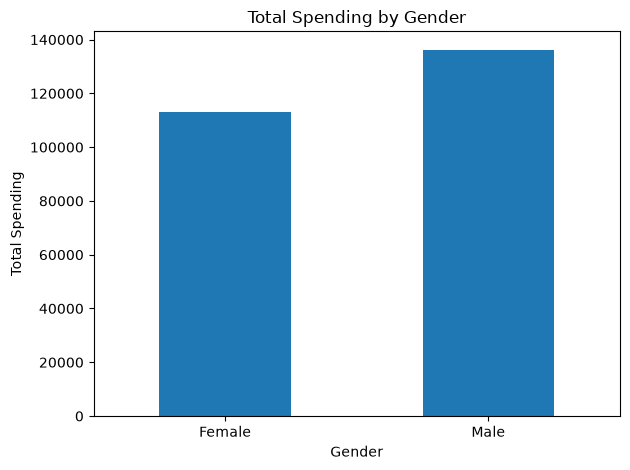

In [32]:
#Spending by gender

gender_analysis['TotalSpent'].plot(
    kind='bar', title='Total Spending by Gender'
)
plt.ylabel('Total Spending')
plt.xlabel('Gender')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

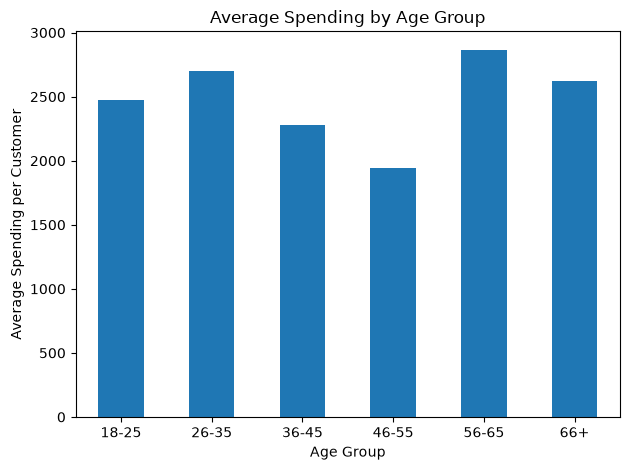

In [33]:
# Avg. customer spending by age group

age_analysis['AvgSpent'].plot(
    kind='bar', title='Average Spending by Age Group'
)
plt.ylabel('Average Spending per Customer')
plt.xlabel('Age Group')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

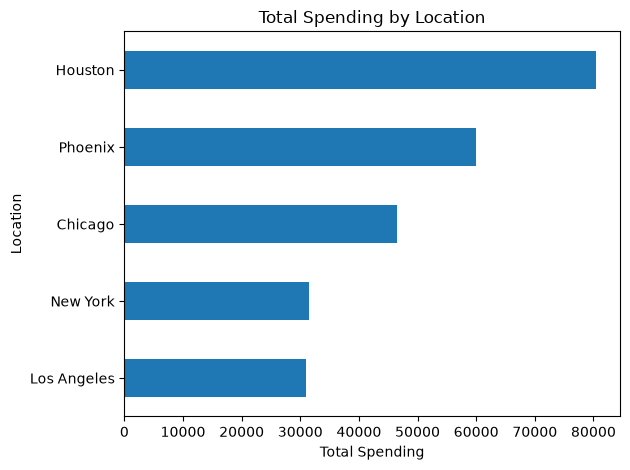

In [34]:
# Spending by location 

location_analysis['TotalSpent'].sort_values().plot(
    kind='barh', title='Total Spending by Location'
)
plt.xlabel('Total Spending')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

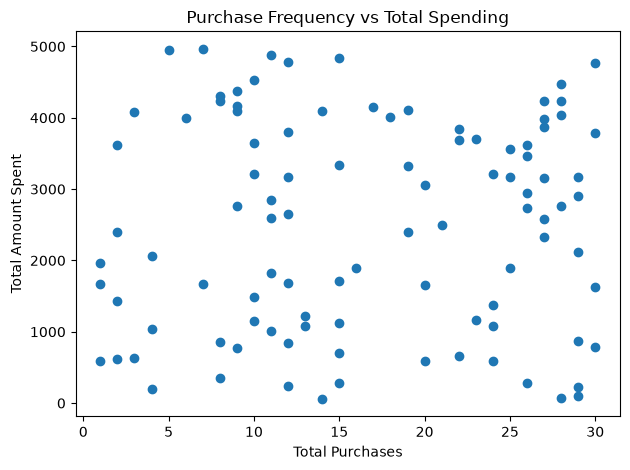

In [35]:
#Purchase frequency vs spending total

plt.scatter(
    df['TotalPurchases'],
    df['TotalAmountSpent']
)
plt.title('Purchase Frequency vs Total Spending')
plt.xlabel('Total Purchases')
plt.ylabel('Total Amount Spent')
plt.tight_layout()
plt.show()

In [36]:
# Sort customers by total spending (CLV analysis)


top_customers = df.sort_values(
    by='TotalAmountSpent',
    ascending=False
)

print(top_customers[
    ['CustomerID', 'Age', 'Gender', 'Location',
     'TotalPurchases', 'TotalAmountSpent']
].head(10))

    CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent
97          98   60    Male      Houston               7           4966.48
38          39   18  Female      Phoenix               5           4947.37
44          45   69  Female      Houston              11           4880.54
42          43   66  Female      Houston              15           4835.52
40          41   20  Female      Phoenix              12           4785.73
78          79   43    Male      Chicago              30           4766.31
63          64   57    Male      Houston              10           4532.50
33          34   43  Female      Chicago              28           4467.34
87          88   49  Female      Houston               9           4380.05
23          24   31    Male  Los Angeles               8           4302.12


In [37]:
# Customer segment

df['CustomerSegment'] = pd.qcut(
    df['TotalAmountSpent'],
    q=4,
    labels=['Low Value', 'Medium Value',
            'High Value', 'Very High Value']
)

print(df.groupby(
    'CustomerSegment', observed=True
)['TotalAmountSpent'].agg(
    ['count', 'mean', 'sum']
).round(2))

                 count     mean        sum
CustomerSegment                           
Low Value           25   581.80   14545.01
Medium Value        25  1822.07   45551.64
High Value          25  3251.94   81298.43
Very High Value     25  4320.95  108023.76


**Insights and business recommendations**

Insight 1: Gender-based purchasing trends
Finding: Female customers make more purchases on average (17.10) than male customers (16.14). However, male customers have higher average spending per customer (2,725.17 versus 2,263.20) and a higher average purchase value (168.85 versus 132.35).

Recommendation:
- Offer product bundles and complementary products to female customers to increase average transaction value.
- Provide loyalty rewards to encourage repeat purchases.
- Test premium product recommendations and targeted offers for male customers.

Insight 2: Age-based spending patterns
Finding: Customers aged 56–65 generate the highest total spending (60,198.61) and have the highest average spending per customer (2,866.60). They also have the highest average purchase value (172.49).

Recommendation:
- Prioritize the 56–65 age group for customer retention campaigns.
- Offer loyalty benefits and personalized product suggestions based on their purchase history.
- Test marketing campaigns for younger groups to understand how to improve their spending.

Insight 3: Location-based revenue trends
Finding: Houston generates the highest total revenue (80,502.02), with 32 customers. Phoenix has the highest average spending per customer (2,855.44) and the highest average purchase value (172.31).

Recommendation:
- Maintain customer engagement and loyalty programs in Houston.
- Investigate which products, campaigns, or customer characteristics contribute to Phoenix's higher average spending.
- Explore opportunities to grow the customer base in New York and Los Angeles.

Insight 4: High-value customer identification
Finding: Customer 98 is the highest spender, with total spending of 4,966.48. Customer 39 has spent 4,947.37 despite making only five purchases.

Recommendation:
- Develop a VIP customer program for high-spending customers.
- Send personalized offers based on previous purchases.
- Encourage customers with high transaction values but lower purchase frequency to return more often.
- Monitor customer activity before offering expensive retention incentives.

Insight 5: Purchase frequency and transaction value
Finding: Female customers purchase slightly more frequently, whereas male customers spend more per transaction. Across all customers, the correlation between purchase count and total spending is approximately 0.06, indicating almost no linear relationship in this sample.

Recommendation:
- Analyze purchase frequency and transaction value as separate customer behaviors.
- Test cross-selling and product bundles to increase transaction value.
- Use loyalty campaigns to encourage repeat purchases among customers with low purchase frequency.

Insight 6: Customer segmentation and personalized marketing
Finding: Customers differ in their total spending, purchase frequency, age, gender, and location. A single marketing strategy may therefore not work equally well for everyone.

Recommendation:
- Segment customers into low-, medium-, high-, and very-high-spending groups.
- Offer exclusive rewards to high-value customers.
- Use personalized discounts to encourage repeat purchases among lower-frequency customers.
- Measure campaign success using repeat purchase rate, average purchase value, and revenue generated.

Insight 7: Customer churn and retention
Finding: The dataset contains a last purchase date for each customer, but it does not contain an agreed churn definition, a customer status field, or a complete transaction timeline. Therefore, an actual churn rate cannot be established reliably from these fields alone.

Recommendation:
- Define a churn rule appropriate to the retailer's normal purchase cycle.
- Track days since last purchase, repeat purchase rates, and customer inactivity.
- Once transaction history is available, identify inactive customers and test targeted win-back campaigns.

**Final conclusion**

The analysis of 100 customers reveals several opportunities for data-driven marketing decisions.
- Most valuable age segment: Customers aged 56–65 have the highest average spending per customer.
- Highest-revenue location: Houston generates the highest total revenue.
- Highest average spending per customer by location: Phoenix.
- Gender-based trend: Male customers spend more per customer and per purchase, while female customers purchase slightly more frequently.
- Customer retention opportunity: High-spending customers should receive personalized loyalty offers, while lower-frequency customers may benefit from repeat-purchase campaigns.